<a href="https://colab.research.google.com/github/Bibatshu95/Hum-to-Harmony/blob/main/notebook/03_lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone -q https://github.com/jukedeck/nottingham-dataset.git
!pip install -q pretty_midi librosa
import glob, random, warnings, numpy as np, pretty_midi, torch, torch.nn as nn
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
torch.manual_seed(42); random.seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)     # should say: cuda

Using: cpu


In [2]:
DUR_BINS = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0]   # note lengths in beats
def dur_class(beats):
    return int(np.argmin([abs(beats - d) for d in DUR_BINS]))

tunes = []
for f in sorted(glob.glob("nottingham-dataset/MIDI/melody/*.mid")):
    pm = pretty_midi.PrettyMIDI(f)
    ks = pm.key_signature_changes
    tonic = ks[0].key_number % 12 if ks else 0
    shift = -tonic if tonic <= 6 else 12 - tonic          # transpose so the tune is in C
    beat = 60 / pm.get_tempo_changes()[1][0]
    notes = sorted(pm.instruments[0].notes, key=lambda n: n.start)
    seq = [(n.pitch + shift, dur_class((n.end - n.start) / beat)) for n in notes if n.end > n.start]
    if len(seq) >= 16:
        tunes.append(seq)

pitches = sorted({p for t in tunes for p, _ in t})
P2I = {p: i for i, p in enumerate(pitches)}
print("Tunes:", len(tunes), "| different pitches:", len(pitches))

Tunes: 1034 | different pitches: 41


In [3]:
random.shuffle(tunes)
cut = int(0.8 * len(tunes))
train_tunes, test_tunes = tunes[:cut], tunes[cut:]

SEQ = 32   # the model sees 32 notes at a time
def make_windows(ts):
    out = []
    for t in ts:
        a = np.array([(P2I[p], d) for p, d in t])
        for k in range(0, len(a) - SEQ, SEQ // 2):
            out.append(a[k:k + SEQ + 1])
    return torch.tensor(np.array(out))

Xtr, Xte = make_windows(train_tunes), make_windows(test_tunes)
print("Training windows:", len(Xtr), "| test windows:", len(Xte))

Training windows: 8596 | test windows: 2108


In [4]:
class MelodyLSTM(nn.Module):
    def __init__(self, n_pitch, n_dur, emb=64, hidden=256, layers=2, dropout=0.3):
        super().__init__()
        self.pitch_emb = nn.Embedding(n_pitch, emb)
        self.dur_emb = nn.Embedding(n_dur, 16)
        self.lstm = nn.LSTM(emb + 16, hidden, layers, batch_first=True, dropout=dropout)
        self.pitch_out = nn.Linear(hidden, n_pitch)
        self.dur_out = nn.Linear(hidden, n_dur)
    def forward(self, p, d, state=None):
        x = torch.cat([self.pitch_emb(p), self.dur_emb(d)], dim=-1)
        h, state = self.lstm(x, state)
        return self.pitch_out(h), self.dur_out(h), state

model = MelodyLSTM(len(pitches), len(DUR_BINS)).to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 887793


In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
loss_fn = nn.CrossEntropyLoss()

def run_epoch(X, train=True):
    model.train(train)
    total_loss, hits, count = 0.0, 0, 0
    for i in range(0, len(X), 64):
        batch = X[i:i + 64].to(device)
        p, d = batch[..., 0], batch[..., 1]
        with torch.set_grad_enabled(train):
            lp, ld, _ = model(p[:, :-1], d[:, :-1])
            loss = (loss_fn(lp.reshape(-1, lp.size(-1)), p[:, 1:].reshape(-1)) +
                    loss_fn(ld.reshape(-1, ld.size(-1)), d[:, 1:].reshape(-1)))
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
        total_loss += loss.item() * len(batch)
        hits += (lp.argmax(-1) == p[:, 1:]).sum().item(); count += p[:, 1:].numel()
    return total_loss / len(X), hits / count

EPOCHS = 10
history = {"train_loss": [], "test_loss": [], "test_acc": []}
best = float("inf")
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(Xtr[torch.randperm(len(Xtr))], train=True)
    te_loss, te_acc = run_epoch(Xte, train=False)
    history["train_loss"].append(tr_loss); history["test_loss"].append(te_loss); history["test_acc"].append(te_acc)
    mark = ""
    if te_loss < best:
        best = te_loss; torch.save(model.state_dict(), "best_lstm.pt"); mark = "  <- best so far, saved"
    print(f"Epoch {epoch:2d} | train loss {tr_loss:.3f} | test loss {te_loss:.3f} | test pitch accuracy {te_acc:.1%}{mark}")

Epoch  1 | train loss 3.009 | test loss 2.695 | test pitch accuracy 35.7%  <- best so far, saved
Epoch  2 | train loss 2.498 | test loss 2.541 | test pitch accuracy 40.1%  <- best so far, saved
Epoch  3 | train loss 2.303 | test loss 2.441 | test pitch accuracy 40.7%  <- best so far, saved
Epoch  4 | train loss 2.134 | test loss 2.405 | test pitch accuracy 41.4%  <- best so far, saved
Epoch  5 | train loss 1.997 | test loss 2.417 | test pitch accuracy 41.9%
Epoch  6 | train loss 1.869 | test loss 2.442 | test pitch accuracy 41.8%
Epoch  7 | train loss 1.754 | test loss 2.489 | test pitch accuracy 41.7%
Epoch  8 | train loss 1.647 | test loss 2.541 | test pitch accuracy 41.1%
Epoch  9 | train loss 1.547 | test loss 2.598 | test pitch accuracy 41.0%
Epoch 10 | train loss 1.462 | test loss 2.659 | test pitch accuracy 40.9%


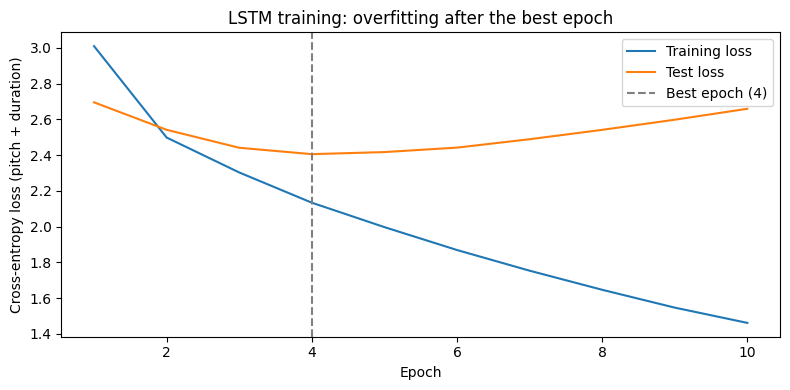

Using best model from epoch 4 (test pitch accuracy 41.4%)


In [6]:
ep = range(1, EPOCHS + 1)
best_ep = int(np.argmin(history["test_loss"])) + 1
plt.figure(figsize=(8, 4))
plt.plot(ep, history["train_loss"], label="Training loss")
plt.plot(ep, history["test_loss"], label="Test loss")
plt.axvline(best_ep, ls="--", c="grey", label=f"Best epoch ({best_ep})")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss (pitch + duration)")
plt.title("LSTM training: overfitting after the best epoch")
plt.legend(); plt.tight_layout(); plt.savefig("lstm_loss_curve.png", dpi=150); plt.show()

model.load_state_dict(torch.load("best_lstm.pt"))
print(f"Using best model from epoch {best_ep} (test pitch accuracy {history['test_acc'][best_ep-1]:.1%})")

In [7]:
!for i in 1 2 3 4 5; do ffmpeg -loglevel error -y -i "hum $i.mp4" -vn -ac 1 -ar 22050 "hum_$i.wav"; done
import librosa
from collections import Counter, defaultdict
from IPython.display import Audio, display

def transcribe(file, gate_db=25, min_len=0.1):
    y, sr = librosa.load(file, sr=22050)
    f0, voiced, _ = librosa.pyin(y, fmin=librosa.note_to_hz("C2"), fmax=librosa.note_to_hz("C6"), sr=sr)
    times = librosa.times_like(f0, sr=sr); keep = voiced.copy()
    rms = librosa.feature.rms(y=y)[0][:len(f0)]
    keep &= librosa.amplitude_to_db(rms, ref=np.max) > -gate_db      # loudness gate (experiment 3)
    midi = np.round(np.where(keep, librosa.hz_to_midi(f0), np.nan))
    notes, cur, start = [], None, 0.0
    for t, m in zip(times, midi):
        m = None if np.isnan(m) else int(m)
        if m != cur:
            if cur is not None and t - start >= min_len: notes.append(cur)
            cur, start = m, t
    if cur is not None and times[-1] - start >= min_len: notes.append(cur)
    return notes   # MIDI numbers

hums = {i: transcribe(f"hum_{i}.wav") for i in range(1, 6)}
for i, h in hums.items():
    print(f"hum_{i}:", [librosa.midi_to_note(p) for p in h])

hum_1: ['B2', 'D♯3', 'E3', 'D♯3', 'E3', 'D♯3', 'F♯3', 'D♯3', 'A♯2', 'C♯3', 'D♯3', 'E3', 'E3', 'F♯3', 'D♯3', 'B2', 'D3', 'C3']
hum_2: ['D♯3', 'D♯3', 'D♯3', 'D♯3', 'D♯3', 'D♯3', 'F♯3', 'F♯3', 'B2', 'D♯3']
hum_3: ['C3', 'G♯3', 'G3', 'G♯3', 'G♯3', 'G♯3', 'G♯3', 'G♯3', 'D3', 'G♯3', 'A3', 'A♯3', 'A3']
hum_4: ['C3', 'C3', 'C3', 'G3', 'G3', 'A3', 'A3', 'G♯3', 'G3']
hum_5: ['C3', 'F3', 'F♯3', 'G3', 'F3', 'F♯3', 'E3', 'E3', 'C3', 'F♯3', 'G3', 'F3', 'E3', 'D3', 'C3', 'F3', 'E3']


In [8]:
MAJOR_PROFILE = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09, 2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
MAJOR_SCALE = {0, 2, 4, 5, 7, 9, 11}

def estimate_key(ps):
    """Krumhansl-Schmuckler key finding: which major key fits these notes best?"""
    h = np.bincount(np.array(ps) % 12, minlength=12)
    return int(np.argmax([np.corrcoef(h, np.roll(MAJOR_PROFILE, k))[0, 1] for k in range(12)]))

@torch.no_grad()
def lstm_continue(hum, n=12, temp=1.0):
    model.eval()
    tonic = estimate_key(hum); shift = -tonic if tonic <= 6 else 12 - tonic   # move hum to C
    ps = [p + shift for p in hum]; octave = 0
    while np.mean(ps) + octave < np.mean(pitches) - 6: octave += 12           # your voice is lower than the data
    ps = [min(pitches, key=lambda q: abs(q - (p + octave))) for p in ps]
    p = torch.tensor([[P2I[x] for x in ps]], device=device)
    d = torch.full_like(p, DUR_BINS.index(1.0))
    lp, ld, state = model(p, d); out = []
    for _ in range(n):
        pi = torch.multinomial(torch.softmax(lp[0, -1] / temp, -1), 1).item()
        di = torch.multinomial(torch.softmax(ld[0, -1] / temp, -1), 1).item()
        out.append((pitches[pi] - shift - octave, DUR_BINS[di]))   # move back to your key and range
        lp, ld, state = model(torch.tensor([[pi]], device=device), torch.tensor([[di]], device=device), state)
    return out

# Markov baseline (rebuilt here so we can compare in one notebook)
raw = [[n.pitch for n in sorted(pretty_midi.PrettyMIDI(f).instruments[0].notes, key=lambda n: n.start)]
       for f in sorted(glob.glob("nottingham-dataset/MIDI/melody/*.mid"))]
counts, overall = defaultdict(Counter), Counter()
for t in raw:
    iv = [b - a for a, b in zip(t, t[1:])]; overall.update(iv)
    for k in range(2, len(iv)): counts[tuple(iv[k-2:k])][iv[k]] += 1

def markov_continue(hum, n=12, temp=1.0):
    iv = [b - a for a, b in zip(hum, hum[1:])]; out = [hum[-1]]
    for _ in range(n):
        c = counts.get(tuple(iv[-2:])) or overall; keys = list(c)
        pr = np.array([c[k] for k in keys], float) ** (1 / temp)
        s = int(np.random.choice(keys, p=pr / pr.sum())); iv.append(s); out.append(out[-1] + s)
    return [(p, 1.0) for p in out[1:]]

def in_key(hum, cont):
    tonic = estimate_key(hum)
    return np.mean([((p - tonic) % 12) in MAJOR_SCALE for p, _ in cont])

temp 0.5: Markov 55% in key | LSTM 100% in key
temp 1.0: Markov 60% in key | LSTM 98% in key
temp 1.5: Markov 54% in key | LSTM 90% in key


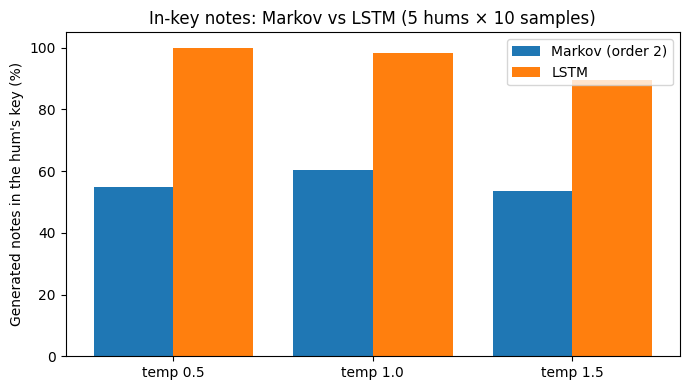

In [9]:
np.random.seed(0); torch.manual_seed(0)
temps, mk_scores, ls_scores = [0.5, 1.0, 1.5], [], []
for temp in temps:
    mk = [in_key(h, markov_continue(h, 12, temp)) for h in hums.values() for _ in range(10)]
    ls = [in_key(h, lstm_continue(h, 12, temp)) for h in hums.values() for _ in range(10)]
    mk_scores.append(np.mean(mk)); ls_scores.append(np.mean(ls))
    print(f"temp {temp}: Markov {np.mean(mk):.0%} in key | LSTM {np.mean(ls):.0%} in key")

x = np.arange(len(temps))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, [s * 100 for s in mk_scores], 0.4, label="Markov (order 2)")
plt.bar(x + 0.2, [s * 100 for s in ls_scores], 0.4, label="LSTM")
plt.xticks(x, [f"temp {t}" for t in temps])
plt.ylabel("Generated notes in the hum's key (%)"); plt.ylim(0, 105)
plt.title("In-key notes: Markov vs LSTM (5 hums × 10 samples)")
plt.legend(); plt.tight_layout(); plt.savefig("markov_vs_lstm_inkey.png", dpi=150); plt.show()

In [10]:
def play(notes, beat=0.4):
    pm = pretty_midi.PrettyMIDI(); inst = pretty_midi.Instrument(program=0); t = 0
    for p, d in notes:
        inst.notes.append(pretty_midi.Note(velocity=90, pitch=int(p), start=t, end=t + d * beat * 0.95)); t += d * beat
    pm.instruments.append(inst)
    return Audio(pm.synthesize(fs=22050), rate=22050)

torch.manual_seed(1); np.random.seed(1)
for i, h in hums.items():
    hum_notes = [(p, 1.0) for p in h]
    for name, fn in [("Markov", markov_continue), ("LSTM", lstm_continue)]:
        cont = fn(h, 12, 1.0)
        print(f"hum_{i} + {name}:", [librosa.midi_to_note(p) for p, _ in cont])
        display(play(hum_notes + cont))

hum_1 + Markov: ['B2', 'C3', 'B2', 'C3', 'A2', 'G2', 'A2', 'B2', 'C3', 'D3', 'E3', 'D3']


hum_1 + LSTM: ['E3', 'A♯3', 'G♯3', 'C♯3', 'E3', 'F3', 'C♯3', 'E3', 'D♯3', 'B2', 'B2', 'F♯3']


hum_2 + Markov: ['F♯3', 'F♯3', 'D♯3', 'C♯3', 'B2', 'C♯3', 'D3', 'C♯3', 'B2', 'G2', 'B2', 'C3']


hum_2 + LSTM: ['G♯3', 'G♯3', 'D♯3', 'G♯3', 'B3', 'A♯3', 'G♯3', 'G3', 'F3', 'D♯3', 'D3', 'C3']


hum_3 + Markov: ['G3', 'A♯3', 'D4', 'G4', 'D4', 'F4', 'D4', 'C4', 'A♯4', 'A4', 'F4', 'F4']


hum_3 + LSTM: ['A♯3', 'G3', 'D♯3', 'D♯4', 'C♯4', 'C4', 'A♯3', 'G3', 'G♯3', 'G3', 'D♯3', 'F3']


hum_4 + Markov: ['A3', 'A3', 'A3', 'C♯4', 'F♯4', 'G♯4', 'A♯4', 'A♯4', 'A♯4', 'C5', 'C5', 'C5']


hum_4 + LSTM: ['F3', 'E3', 'E3', 'D3', 'C3', 'E3', 'D3', 'C3', 'D3', 'E3', 'D3', 'C3']


hum_5 + Markov: ['D3', 'C3', 'B2', 'C3', 'A2', 'G2', 'F2', 'E2', 'F2', 'D2', 'B1', 'C2']


hum_5 + LSTM: ['G3', 'G3', 'F3', 'E3', 'E3', 'E3', 'E3', 'D3', 'B2', 'B2', 'A2', 'E3']
